# 01 — Data understanding, cleaning and EDA

**Project:** Predicting loan default for thin-file borrowers using alternative data
**Data:** Home Credit Default Risk — official Kaggle competition by Home Credit Group
(https://www.kaggle.com/competitions/home-credit-default-risk). See `data/README.md` for files and provenance.

This notebook explores `application_train` (the labelled applicants), defines the cleaning step
(`src/cleaning.py`), and looks at how default rates vary across applicant characteristics and
credit-history availability. No model is fitted here.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from src.cleaning import clean_application, days_employed_anomaly_report, income_outlier_report
from src.config import ID, PROCESSED_DIR, TARGET
from src.eda import binned_rate_table, default_rate_table, missing_table
from src.features import add_application_ratios, add_history_flags
from src.plotting import DEFAULT, INK_2, MUTED, REPAID, SERIES, plot_rate_bars, savefig, set_style

set_style()
pd.set_option("display.max_columns", 60, "display.width", 160, "display.max_colwidth", 140)

## 1. Load `application_train`

In [2]:
app = pd.read_parquet(PROCESSED_DIR / "application_train.parquet")
print("shape:", app.shape)
print("unique SK_ID_CURR:", app[ID].nunique())
display(app.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("n_columns"))

shape: (307511, 122)
unique SK_ID_CURR: 307511


,n_columns
dtype,
float32,65
int8,37
category,16
int32,2
int16,2


,applicants,pct
TARGET,,
0,"282,686",91.93%
1,"24,825",8.07%


repaid applicants per default: 11.39
saved reports/figures/01_target_distribution.png


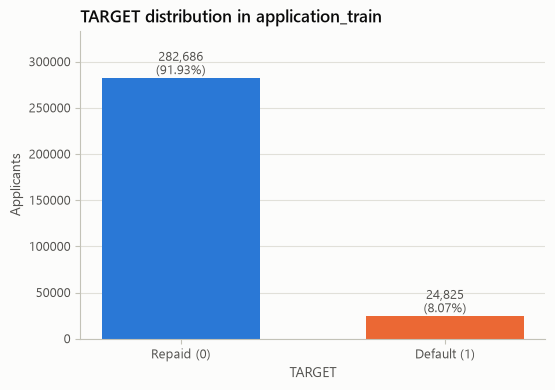

In [3]:
target_counts = app[TARGET].value_counts().sort_index()
target_table = pd.DataFrame({
    "applicants": target_counts,
    "pct": target_counts / len(app) * 100,
}, index=pd.Index([0, 1], name=TARGET))
display(target_table.style.format({"applicants": "{:,}", "pct": "{:.2f}%"}))
print(f"repaid applicants per default: {target_counts[0] / target_counts[1]:.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Repaid (0)", "Default (1)"], target_counts.values, color=[REPAID, DEFAULT], width=0.6)
for bar, n, pct in zip(bars, target_counts.values, target_table["pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({pct:.2f}%)", ha="center", va="bottom",
            fontsize=9, color=INK_2)
ax.set_ylim(0, target_counts.max() * 1.18)
ax.set_title("TARGET distribution in application_train", loc="left")
ax.set_xlabel("TARGET")
ax.set_ylabel("Applicants")
ax.grid(axis="x", visible=False)
savefig(fig, "01_target_distribution.png")
plt.show()

**Insight:** The classes are heavily imbalanced: 24,825 defaults (8.07%) against 282,686 repaid loans (91.93%),
i.e. 11.39 repaid applicants per default. A model that predicts "repaid" for everyone would already be 91.93%
accurate, so accuracy is not a useful metric here; the modelling uses AUC, PR-AUC and class weighting instead.

## 2. Missing values

In [4]:
miss = missing_table(app)
n_over_50 = int((miss["pct_missing"] > 50).sum())
building_cols = [c for c in miss.index if c.endswith(("_AVG", "_MODE", "_MEDI"))]
print(f"columns with any missing value: {len(miss)} of {app.shape[1]}")
print(f"columns with >50% missing: {n_over_50}")
print(f"  of which building-information columns (*_AVG/_MODE/_MEDI): "
      f"{sum(miss.loc[c, 'pct_missing'] > 50 for c in building_cols)}")
display(miss.head(30).style.format({"n_missing": "{:,}", "pct_missing": "{:.1f}%"}))

columns with any missing value: 67 of 122
columns with >50% missing: 41
  of which building-information columns (*_AVG/_MODE/_MEDI): 39


,n_missing,pct_missing
COMMONAREA_MEDI,"214,865",69.9%
COMMONAREA_MODE,"214,865",69.9%
COMMONAREA_AVG,"214,865",69.9%
NONLIVINGAPARTMENTS_MODE,"213,514",69.4%
NONLIVINGAPARTMENTS_MEDI,"213,514",69.4%
NONLIVINGAPARTMENTS_AVG,"213,514",69.4%
FONDKAPREMONT_MODE,"210,295",68.4%
LIVINGAPARTMENTS_AVG,"210,199",68.4%
LIVINGAPARTMENTS_MEDI,"210,199",68.4%
LIVINGAPARTMENTS_MODE,"210,199",68.4%


saved reports/figures/02_missing_values_top30.png


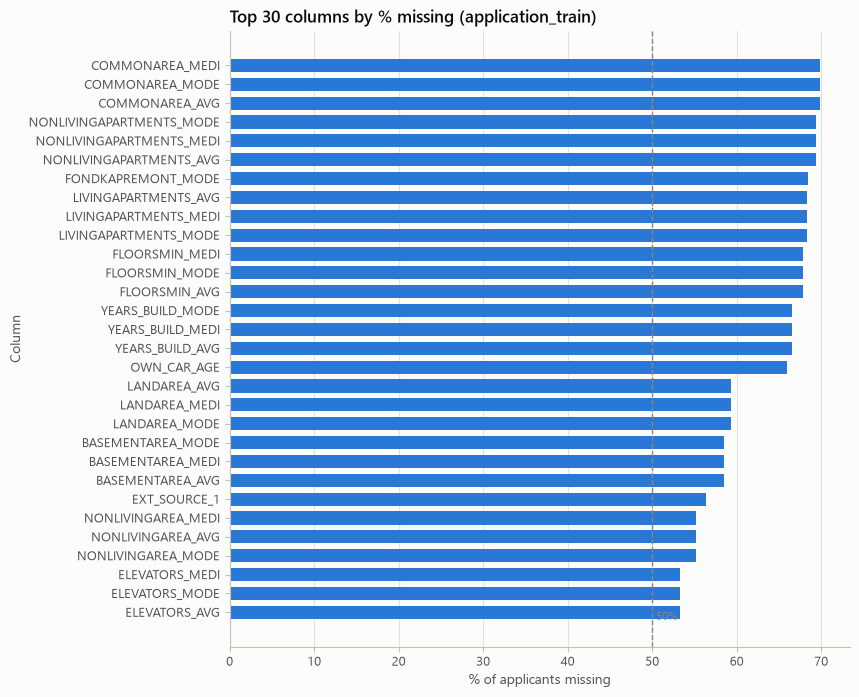

In [5]:
top30 = miss.head(30)
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top30.index, top30["pct_missing"], color=SERIES[0], height=0.7)
ax.invert_yaxis()
ax.axvline(50, color=MUTED, linestyle="--", linewidth=1)
ax.text(50.5, 29.4, "50%", color=MUTED, fontsize=8)
ax.set_title("Top 30 columns by % missing (application_train)", loc="left")
ax.set_xlabel("% of applicants missing")
ax.set_ylabel("Column")
ax.grid(axis="y", visible=False)
savefig(fig, "02_missing_values_top30.png")
plt.show()

**Insight:** 67 of 122 columns have missing values and 41 are more than 50% missing; 39 of those 41 are
building-information columns (`*_AVG`, `*_MODE`, `*_MEDI`, up to 69.9% missing). `EXT_SOURCE_1` (56.4% missing)
is also in this group. Missing values are kept rather than dropped: LightGBM handles NaN natively and the
logistic regression uses median imputation plus missing-value indicator columns.

## 3. Descriptions of key columns
From `HomeCredit_columns_description` (read as latin-1 when converted to Parquet).

In [6]:
desc = pd.read_parquet(PROCESSED_DIR / "HomeCredit_columns_description.parquet")
key_cols = ["TARGET", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "DAYS_BIRTH",
            "DAYS_EMPLOYED", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "NAME_INCOME_TYPE",
            "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "REGION_RATING_CLIENT", "CODE_GENDER"]
key_desc = (desc[desc["Table"].astype(str).str.startswith("application")]
            .set_index("Row").loc[key_cols, ["Description", "Special"]])
display(key_desc)

,Description,Special
Row,,
TARGET,Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installme...,NaN
AMT_INCOME_TOTAL,Income of the client,NaN
AMT_CREDIT,Credit amount of the loan,NaN
AMT_ANNUITY,Loan annuity,NaN
AMT_GOODS_PRICE,For consumer loans it is the price of the goods for which the loan is given,NaN
DAYS_BIRTH,Client's age in days at the time of application,time only relative to the application
DAYS_EMPLOYED,How many days before the application the person started current employment,time only relative to the application
EXT_SOURCE_1,Normalized score from external data source,normalized
EXT_SOURCE_2,Normalized score from external data source,normalized


## 4. Cleaning (`src/cleaning.py::clean_application`)

### 4a. `DAYS_EMPLOYED == 365243` anomaly

In [7]:
anom_report = days_employed_anomaly_report(app)
display(anom_report.style.format({"applicants": "{:,}", "share": "{:.2%}", "default_rate": "{:.2%}"}))
anomalous = app["DAYS_EMPLOYED"] == 365243
print("NAME_INCOME_TYPE of the anomalous rows:")
print(app.loc[anomalous, "NAME_INCOME_TYPE"].value_counts().loc[lambda s: s > 0].to_string())

,applicants,share,default_rate
DAYS_EMPLOYED = 365243,"55,374",18.01%,5.40%
valid DAYS_EMPLOYED,"252,137",81.99%,8.66%


NAME_INCOME_TYPE of the anomalous rows:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22


### 4b. `CODE_GENDER == 'XNA'` and applying the cleaning function

In [8]:
xna = app["CODE_GENDER"] == "XNA"
print(f"CODE_GENDER == 'XNA': {int(xna.sum())} rows, defaults among them: {int(app.loc[xna, TARGET].sum())}")

clean = clean_application(app)
print(f"shape before cleaning: {app.shape} -> after: {clean.shape}")
print("new columns:", [c for c in clean.columns if c not in app.columns])
print(f"DAYS_EMPLOYED_ANOM flagged rows: {int(clean['DAYS_EMPLOYED_ANOM'].sum()):,}")
display(clean[["AGE_YEARS", "YEARS_EMPLOYED"]].describe().T)

CODE_GENDER == 'XNA': 4 rows, defaults among them: 0
shape before cleaning: (307511, 122) -> after: (307507, 125)
new columns: ['DAYS_EMPLOYED_ANOM', 'AGE_YEARS', 'YEARS_EMPLOYED']
DAYS_EMPLOYED_ANOM flagged rows: 55,374


,count,mean,std,min,25%,50%,75%,max
AGE_YEARS,307507.0,43.937061,11.956117,20.517809,34.008221,43.150684,53.923286,69.120544
YEARS_EMPLOYED,252133.0,6.531897,6.406377,0.000000,2.101370,4.515069,8.698630,49.073971


### 4c. Extreme `AMT_INCOME_TOTAL` values (reported, not removed)

In [9]:
display(clean["AMT_INCOME_TOTAL"].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).to_frame().T)
threshold, n_above, rate_above, top_income = income_outlier_report(clean, quantile=0.999)
print(f"99.9th percentile of AMT_INCOME_TOTAL: {threshold:,.0f}")
print(f"applicants above it: {n_above}  (default rate {rate_above:.2%})")
print("10 highest incomes:")
display(top_income)

,count,mean,std,min,50%,90%,99%,99.9%,max
AMT_INCOME_TOTAL,307507.0,168797.6875,237124.625,25650.0,147150.0,270000.0,472500.0,900000.0,117000000.0


99.9th percentile of AMT_INCOME_TOTAL: 900,000
applicants above it: 278  (default rate 5.40%)
10 highest incomes:


,SK_ID_CURR,AMT_INCOME_TOTAL,AMT_CREDIT,TARGET
12840,114967,117000000.0,562491.0,1
203689,336147,18000090.0,675000.0,0
246854,385674,13500000.0,1400503.5,0
77766,190160,9000000.0,1431531.0,0
131124,252084,6750000.0,790830.0,0
103003,219563,4500000.0,2250000.0,0
187830,317748,4500000.0,835380.0,0
204560,337151,4500000.0,450000.0,0
287459,432980,4500000.0,1755000.0,0
181695,310601,3950059.5,675000.0,0


**Insight (cleaning):**
- `DAYS_EMPLOYED = 365243` affects 55,374 applicants (18.01%): 55,352 pensioners and 22 unemployed. Their default
  rate is 5.40% vs 8.66% for applicants with a valid value, so the anomaly carries information. It is kept as the
  flag `DAYS_EMPLOYED_ANOM` while the value itself is set to NaN.
- The 4 rows with `CODE_GENDER = 'XNA'` (0 defaults) are dropped, leaving 307,507 applicants.
- `AMT_INCOME_TOTAL` is extremely skewed: median 147,150, 99.9th percentile 900,000, but a maximum of 117,000,000
  (a single applicant who defaulted on a 562,491 loan, plausibly a data-entry error). 278 applicants lie above the
  99.9th percentile, with a default rate of 5.40%. They are kept and flagged here only: tree models are insensitive
  to extreme values, and in the ratio features an extreme income only affects its own row.

## 5. Exploratory analysis
Overall default rate after cleaning is the dashed reference line in each chart.

In [10]:
overall_rate = clean[TARGET].mean()
print(f"overall default rate (cleaned): {overall_rate:.4%}")

overall default rate (cleaned): 8.0730%


### 5a. Default rate by age group

,applicants,share,defaults,default_rate
AGE_YEARS,,,,
20-24,"12,150",4.0%,"1,496",12.31%
25-29,"32,848",10.7%,"3,659",11.14%
30-34,"39,439",12.8%,"4,057",10.29%
35-39,"42,859",13.9%,"3,828",8.93%
40-44,"41,416",13.5%,"3,255",7.86%
45-49,"35,127",11.4%,"2,605",7.42%
50-54,"34,942",11.4%,"2,341",6.70%
55-59,"33,131",10.8%,"1,832",5.53%
60-64,"27,473",8.9%,"1,450",5.28%


saved reports/figures/03_default_rate_by_age_group.png


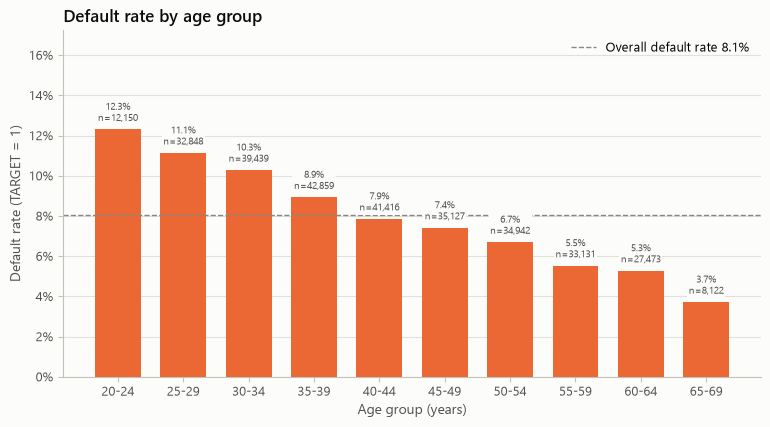

In [11]:
age_bins = list(range(20, 75, 5))
age_labels = [f"{a}-{a + 4}" for a in age_bins[:-1]]
age_table = binned_rate_table(clean, "AGE_YEARS", bins=age_bins, labels=age_labels)
display(age_table.style.format({"applicants": "{:,}", "share": "{:.1%}", "defaults": "{:,}", "default_rate": "{:.2%}"}))

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_rate_bars(age_table, ax, "Default rate by age group", "Age group (years)",
               overall_rate=overall_rate, horizontal=False)
savefig(fig, "03_default_rate_by_age_group.png")
plt.show()

**Insight:** Default risk falls steadily with age, from 12.31% for 20–24 year-olds to 3.72% for 65–69 year-olds,
and every age band from 40 upwards is below the 8.07% average. Age is one of the clearest risk signals that does
not require any credit history.

### 5b. Default rate by applicant categories


NAME_EDUCATION_TYPE


,applicants,share,defaults,default_rate
NAME_EDUCATION_TYPE,,,,
Lower secondary,"3,816",1.2%,417,10.93%
Secondary / secondary special,"218,389",71.0%,"19,524",8.94%
Incomplete higher,"10,276",3.3%,872,8.49%
Higher education,"74,862",24.3%,"4,009",5.36%
Academic degree,164,0.1%,3,1.83%


saved reports/figures/04_default_rate_by_education.png


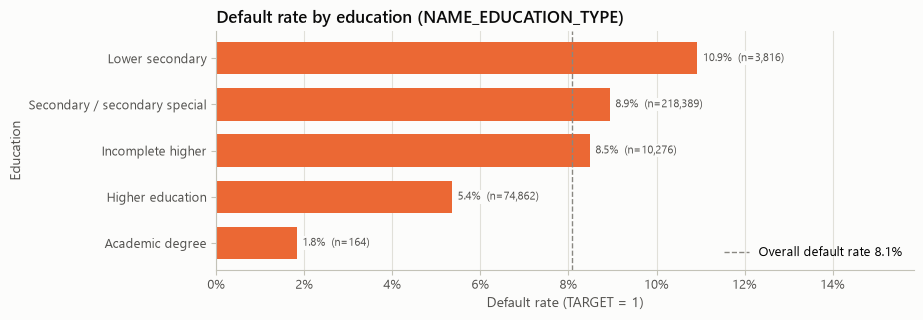


NAME_INCOME_TYPE


,applicants,share,defaults,default_rate
NAME_INCOME_TYPE,,,,
Maternity leave,5,0.0%,2,40.00%
Unemployed,22,0.0%,8,36.36%
Working,"158,771",51.6%,"15,224",9.59%
Commercial associate,"71,616",23.3%,"5,360",7.48%
State servant,"21,703",7.1%,"1,249",5.75%
Pensioner,"55,362",18.0%,"2,982",5.39%
Businessman,10,0.0%,0,0.00%
Student,18,0.0%,0,0.00%


saved reports/figures/05_default_rate_by_income_type.png


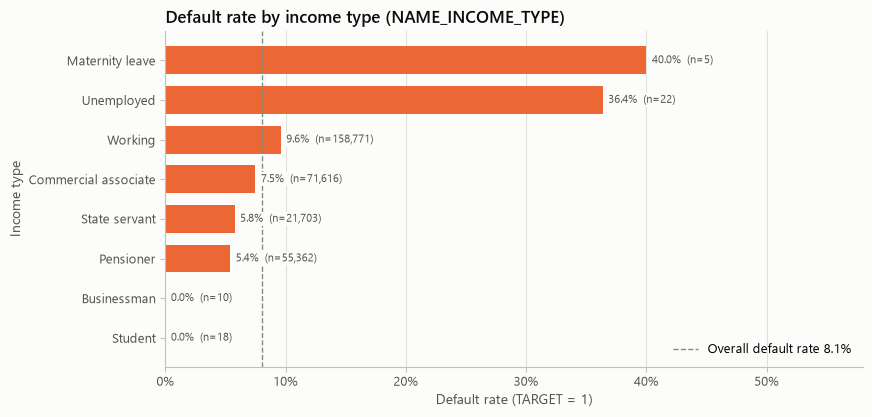


NAME_CONTRACT_TYPE


,applicants,share,defaults,default_rate
NAME_CONTRACT_TYPE,,,,
Cash loans,"278,232",90.5%,"23,221",8.35%
Revolving loans,"29,275",9.5%,"1,604",5.48%


saved reports/figures/06_default_rate_by_contract_type.png


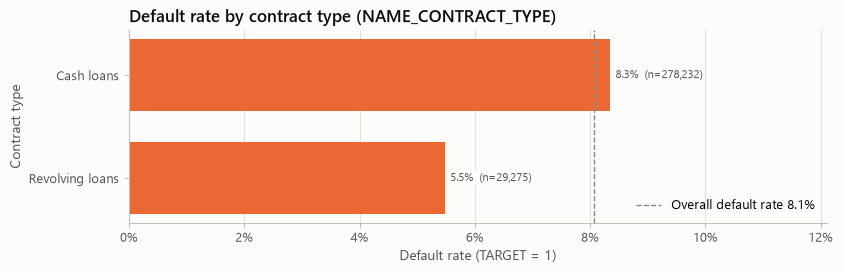


OCCUPATION_TYPE


,applicants,share,defaults,default_rate
OCCUPATION_TYPE,,,,
Low-skill Laborers,"2,092",0.7%,359,17.16%
Drivers,"18,603",6.0%,"2,107",11.33%
Waiters/barmen staff,"1,348",0.4%,152,11.28%
Security staff,"6,721",2.2%,722,10.74%
Laborers,"55,186",17.9%,"5,838",10.58%
Cooking staff,"5,946",1.9%,621,10.44%
Sales staff,"32,102",10.4%,"3,092",9.63%
Cleaning staff,"4,653",1.5%,447,9.61%
Realty agents,751,0.2%,59,7.86%


saved reports/figures/07_default_rate_by_occupation.png


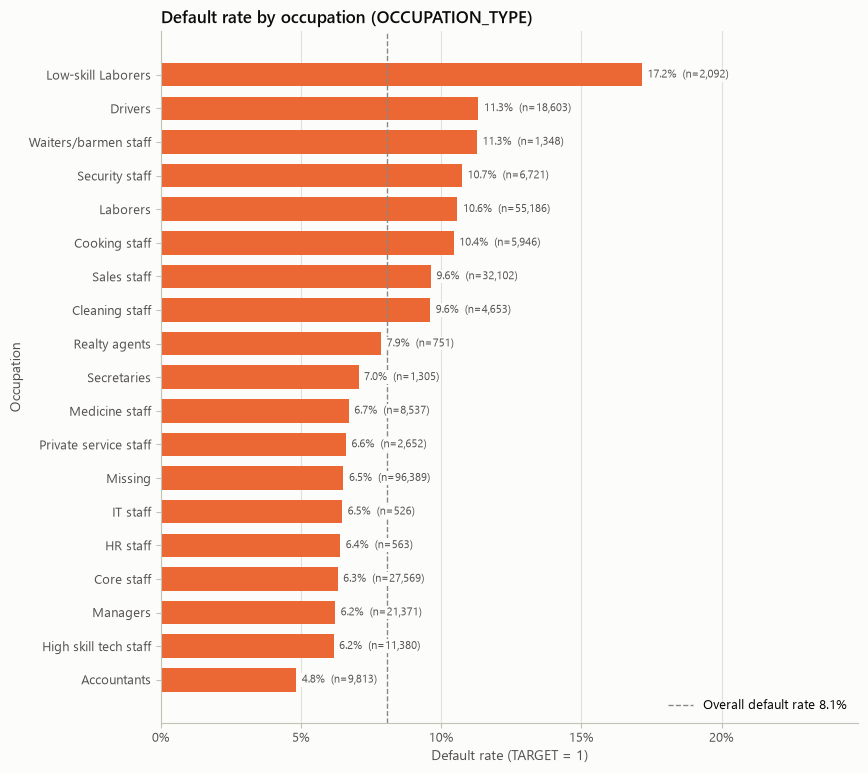


NAME_FAMILY_STATUS


,applicants,share,defaults,default_rate
NAME_FAMILY_STATUS,,,,
Civil marriage,"29,774",9.7%,"2,961",9.94%
Single / not married,"45,444",14.8%,"4,457",9.81%
Separated,"19,770",6.4%,"1,620",8.19%
Married,"196,429",63.9%,"14,850",7.56%
Widow,"16,088",5.2%,937,5.82%
Unknown,2,0.0%,0,0.00%


saved reports/figures/08_default_rate_by_family_status.png


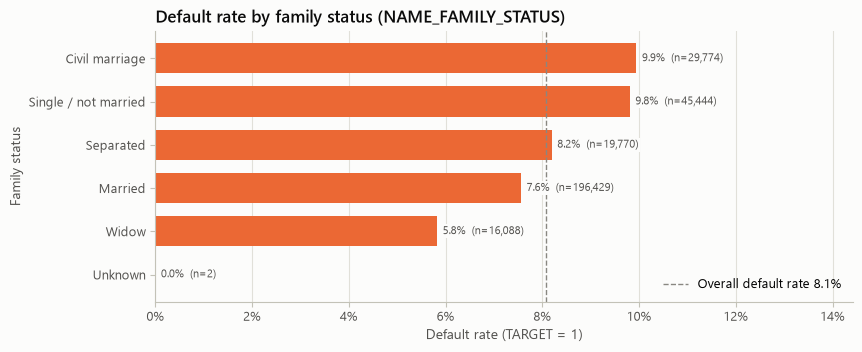

applicants with missing OCCUPATION_TYPE: 96,389; share of them who are pensioners: 57.43%


In [12]:
cat_plots = [
    ("NAME_EDUCATION_TYPE", "Education", "04_default_rate_by_education.png"),
    ("NAME_INCOME_TYPE", "Income type", "05_default_rate_by_income_type.png"),
    ("NAME_CONTRACT_TYPE", "Contract type", "06_default_rate_by_contract_type.png"),
    ("OCCUPATION_TYPE", "Occupation", "07_default_rate_by_occupation.png"),
    ("NAME_FAMILY_STATUS", "Family status", "08_default_rate_by_family_status.png"),
]
cat_tables = {}
for col, label, fname in cat_plots:
    table = default_rate_table(clean, col, sort_by_rate=True)
    cat_tables[col] = table
    print(f"\n{col}")
    display(table.style.format({"applicants": "{:,}", "share": "{:.1%}", "defaults": "{:,}", "default_rate": "{:.2%}"}))
    fig, ax = plt.subplots(figsize=(9, max(2.5, 0.42 * len(table) + 1)))
    plot_rate_bars(table, ax, f"Default rate by {label.lower()} ({col})", label, overall_rate=overall_rate)
    savefig(fig, fname)
    plt.show()

no_occupation = clean["OCCUPATION_TYPE"].isna()
print(f"applicants with missing OCCUPATION_TYPE: {int(no_occupation.sum()):,}; "
      f"share of them who are pensioners: {(clean.loc[no_occupation, 'NAME_INCOME_TYPE'] == 'Pensioner').mean():.2%}")

**Insight:**
- **Education:** lower secondary 10.93% vs higher education 5.36% (academic degree 1.83%, but n=164 only).
- **Income type:** working applicants (51.6% of applicants) default at 9.59%, state servants at 5.75% and pensioners
  at 5.39%. The extreme rates for maternity leave (40.00%, n=5), unemployed (36.36%, n=22), businessmen (0%, n=10)
  and students (0%, n=18) rest on too few applicants to be reliable.
- **Contract type:** cash loans 8.35% vs revolving loans 5.48%.
- **Occupation:** low-skill labourers have the highest rate (17.16%, n=2,092), followed by drivers (11.33%) and
  waiters/barmen (11.28%); accountants have the lowest (4.83%). Occupation is missing for 96,389 applicants (31.3%),
  whose default rate is 6.51%; 57.43% of them are pensioners, which is consistent with the below-average rate.
- **Family status:** civil marriage (9.94%) and single (9.81%) are above average; married (7.56%) and widowed (5.82%)
  are below.

### 5c. External credit scores (`EXT_SOURCE_1/2/3`) by TARGET

,pct_missing,mean_repaid,mean_default,corr_with_TARGET
EXT_SOURCE_1,56.3812,0.5115,0.3870,-0.1553
EXT_SOURCE_2,0.2146,0.5235,0.4109,-0.1605
EXT_SOURCE_3,19.8256,0.5210,0.3907,-0.1789


saved reports/figures/09_ext_source_kde_by_target.png


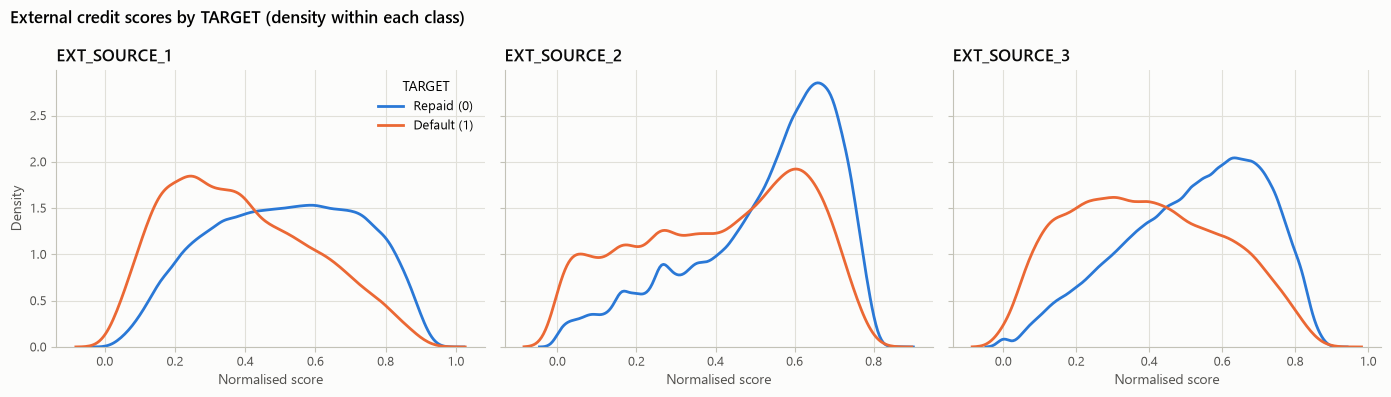

In [13]:
ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
ext_summary = pd.DataFrame({
    "pct_missing": clean[ext_cols].isna().mean() * 100,
    "mean_repaid": clean.loc[clean[TARGET] == 0, ext_cols].mean(),
    "mean_default": clean.loc[clean[TARGET] == 1, ext_cols].mean(),
    "corr_with_TARGET": clean[ext_cols].astype("float64").corrwith(clean[TARGET].astype("float64")),
})
display(ext_summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, col in zip(axes, ext_cols):
    for t, color, name in [(0, REPAID, "Repaid (0)"), (1, DEFAULT, "Default (1)")]:
        sns.kdeplot(clean.loc[clean[TARGET] == t, col].dropna(), ax=ax, color=color, label=name, linewidth=2)
    ax.set_title(col, loc="left")
    ax.set_xlabel("Normalised score")
    ax.set_ylabel("Density")
axes[0].legend(title="TARGET")
fig.suptitle("External credit scores by TARGET (density within each class)", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
savefig(fig, "09_ext_source_kde_by_target.png")
plt.show()

**Insight:** All three external scores are clearly lower for defaulters (mean 0.3870 vs 0.5115 for `EXT_SOURCE_1`,
0.4109 vs 0.5235 for `EXT_SOURCE_2`, 0.3907 vs 0.5210 for `EXT_SOURCE_3`), and they are the three numeric columns
most correlated with TARGET (−0.1553 to −0.1789). The provider only describes them as a "normalized score from
external data source"; they are usually read as external credit scores, i.e. a proxy for credit history, which is
why notebook 04 tests a model without them. `EXT_SOURCE_1` is missing for 56.4% of applicants and `EXT_SOURCE_3`
for 19.8%.

### 5d. Affordability: credit-to-income and annuity-to-income deciles
Ratios come from `src/features.py::add_application_ratios` (the same code used to build the model table).


CREDIT_INCOME_RATIO deciles


,applicants,share,defaults,default_rate
CREDIT_INCOME_RATIO,,,,
"(0.00381, 1.332]","30,759",10.0%,"2,125",6.91%
"(1.332, 1.818]","30,779",10.0%,"2,389",7.76%
"(1.818, 2.266]","30,728",10.0%,"2,493",8.11%
"(2.266, 2.764]","30,772",10.0%,"2,776",9.02%
"(2.764, 3.265]","30,724",10.0%,"2,659",8.65%
"(3.265, 3.907]","30,743",10.0%,"2,827",9.20%
"(3.907, 4.725]","30,752",10.0%,"2,650",8.62%
"(4.725, 5.769]","30,751",10.0%,"2,445",7.95%
"(5.769, 7.488]","30,815",10.0%,"2,293",7.44%



ANNUITY_INCOME_RATIO deciles


,applicants,share,defaults,default_rate
ANNUITY_INCOME_RATIO,,,,
"(-0.000776, 0.08]","31,645",10.3%,"2,258",7.14%
"(0.08, 0.104]","29,855",9.7%,"2,169",7.27%
"(0.104, 0.125]","30,754",10.0%,"2,404",7.82%
"(0.125, 0.144]","30,750",10.0%,"2,412",7.84%
"(0.144, 0.163]","30,756",10.0%,"2,423",7.88%
"(0.163, 0.186]","30,737",10.0%,"2,574",8.37%
"(0.186, 0.213]","30,768",10.0%,"2,627",8.54%
"(0.213, 0.247]","30,754",10.0%,"2,723",8.85%
"(0.247, 0.302]","30,726",10.0%,"2,716",8.84%


saved reports/figures/10_default_rate_by_affordability_deciles.png


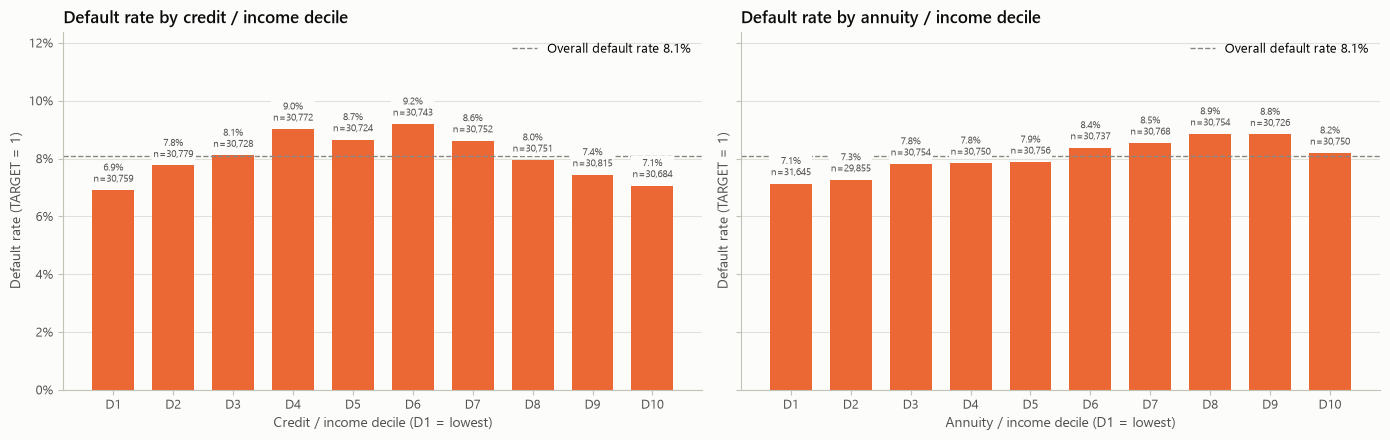

In [14]:
ratios = add_application_ratios(clean)
decile_tables = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, col, label in [(axes[0], "CREDIT_INCOME_RATIO", "Credit / income"),
                       (axes[1], "ANNUITY_INCOME_RATIO", "Annuity / income")]:
    table = binned_rate_table(ratios, col, q=10)
    decile_tables[col] = table
    print(f"\n{col} deciles")
    display(table.style.format({"applicants": "{:,}", "share": "{:.1%}", "defaults": "{:,}", "default_rate": "{:.2%}"}))
    table = table.set_axis([f"D{i}" for i in range(1, len(table) + 1)])
    plot_rate_bars(table, ax, f"Default rate by {label.lower()} decile", f"{label} decile (D1 = lowest)",
                   overall_rate=overall_rate, horizontal=False)
fig.tight_layout()
savefig(fig, "10_default_rate_by_affordability_deciles.png")
plt.show()

**Insight:** On their own, affordability ratios have only a weak and non-monotonic link with default. By
credit-to-income decile the default rate rises from 6.91% (D1) to a peak of 9.20% (D6) and falls back to 7.07% (D10);
by annuity-to-income decile it rises from 7.14% (D1) to 8.85% (D8) and is 8.19% in D10. The spread across deciles
is at most 2.29 percentage points (credit/income) and 1.72 (annuity/income), much smaller than for age or the
external scores, so these ratios are likely to matter mainly in combination with other features.

### 5e. Top 15 numeric features by |correlation| with TARGET
Pearson correlation on the cleaned table (original numeric columns; `AGE_YEARS` / `YEARS_EMPLOYED`
are left out because they are linear rescalings of `DAYS_BIRTH` / `DAYS_EMPLOYED`).

,corr_with_TARGET
EXT_SOURCE_3,-0.1789
EXT_SOURCE_2,-0.1605
EXT_SOURCE_1,-0.1553
DAYS_BIRTH,0.0782
DAYS_EMPLOYED,0.0750
REGION_RATING_CLIENT_W_CITY,0.0609
REGION_RATING_CLIENT,0.0589
DAYS_LAST_PHONE_CHANGE,0.0552
DAYS_ID_PUBLISH,0.0515
REG_CITY_NOT_WORK_CITY,0.0510


saved reports/figures/11_top15_target_correlations.png


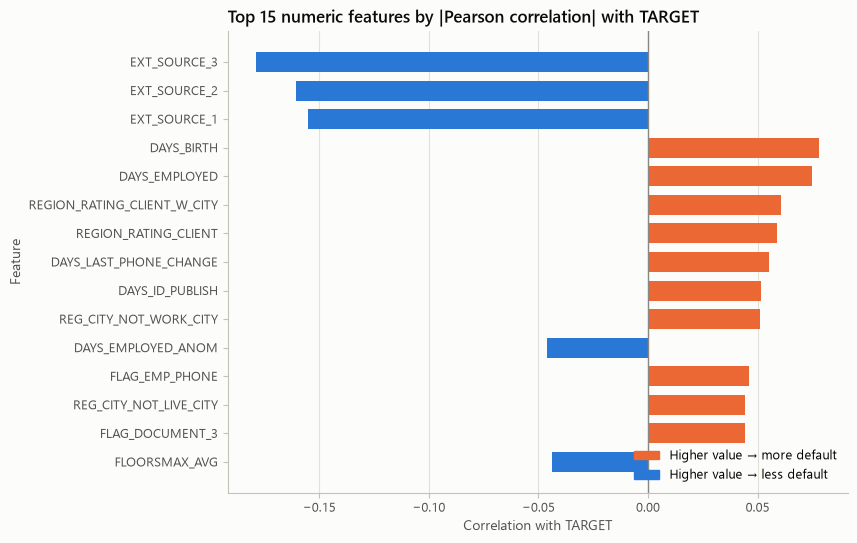

In [15]:
num_cols = [c for c in clean.select_dtypes("number").columns
            if c not in (ID, TARGET, "AGE_YEARS", "YEARS_EMPLOYED")]
corr = clean[num_cols].astype("float64").corrwith(clean[TARGET].astype("float64"))
top15 = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)
display(top15.to_frame("corr_with_TARGET").round(4))

fig, ax = plt.subplots(figsize=(8, 6))
colors = [DEFAULT if v > 0 else REPAID for v in top15.values]
ax.barh(top15.index, top15.values, color=colors, height=0.7)
ax.invert_yaxis()
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_title("Top 15 numeric features by |Pearson correlation| with TARGET", loc="left")
ax.set_xlabel("Correlation with TARGET")
ax.set_ylabel("Feature")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=DEFAULT, label="Higher value → more default"),
                   Patch(color=REPAID, label="Higher value → less default")], loc="lower right")
savefig(fig, "11_top15_target_correlations.png")
plt.show()

**Insight:** The three EXT_SOURCE scores dominate (r = −0.1789, −0.1605, −0.1553). The next strongest linear
signals are age (`DAYS_BIRTH`, r = 0.0782; days are negative, so younger means riskier), employment length
(`DAYS_EMPLOYED`, 0.0750) and the region rating (0.0609 / 0.0589). No column reaches |r| = 0.18, so default
cannot be predicted from any single variable; a multivariate, non-linear model is needed.

### 5f. Thin-file view: who has a credit history?
`HAS_BUREAU_HISTORY` = applicant has at least one row in `bureau` (credit reported by other institutions).
`HAS_PREV_APPLICATION` = applicant has at least one previous application with Home Credit.

In [16]:
bureau_ids = pd.read_parquet(PROCESSED_DIR / "bureau.parquet", columns=[ID])[ID].unique()
prev_ids = pd.read_parquet(PROCESSED_DIR / "previous_application.parquet", columns=[ID])[ID].unique()
flags = add_history_flags(clean, bureau_ids, prev_ids)

flag_tables = {}
for col in ["HAS_BUREAU_HISTORY", "HAS_PREV_APPLICATION"]:
    flag_tables[col] = default_rate_table(flags, col)
    print(f"\n{col}")
    display(flag_tables[col].style.format({"applicants": "{:,}", "share": "{:.2%}", "defaults": "{:,}", "default_rate": "{:.2%}"}))

combo = flags["HAS_BUREAU_HISTORY"].map({1: "bureau", 0: "no bureau"}) + " / " + \
        flags["HAS_PREV_APPLICATION"].map({1: "prev app", 0: "no prev app"})
combo_table = default_rate_table(flags.assign(HISTORY_GROUP=combo), "HISTORY_GROUP", sort_by_rate=True)
print("\nCombined history groups")
display(combo_table.style.format({"applicants": "{:,}", "share": "{:.2%}", "defaults": "{:,}", "default_rate": "{:.2%}"}))


HAS_BUREAU_HISTORY


,applicants,share,defaults,default_rate
HAS_BUREAU_HISTORY,,,,
0,"44,020",14.32%,"4,457",10.12%
1,"263,487",85.68%,"20,368",7.73%



HAS_PREV_APPLICATION


,applicants,share,defaults,default_rate
HAS_PREV_APPLICATION,,,,
0,"16,454",5.35%,980,5.96%
1,"291,053",94.65%,"23,845",8.19%



Combined history groups


,applicants,share,defaults,default_rate
HISTORY_GROUP,,,,
no bureau / prev app,"41,550",13.51%,"4,277",10.29%
bureau / prev app,"249,503",81.14%,"19,568",7.84%
no bureau / no prev app,"2,470",0.80%,180,7.29%
bureau / no prev app,"13,984",4.55%,800,5.72%


saved reports/figures/12_thin_file_groups.png


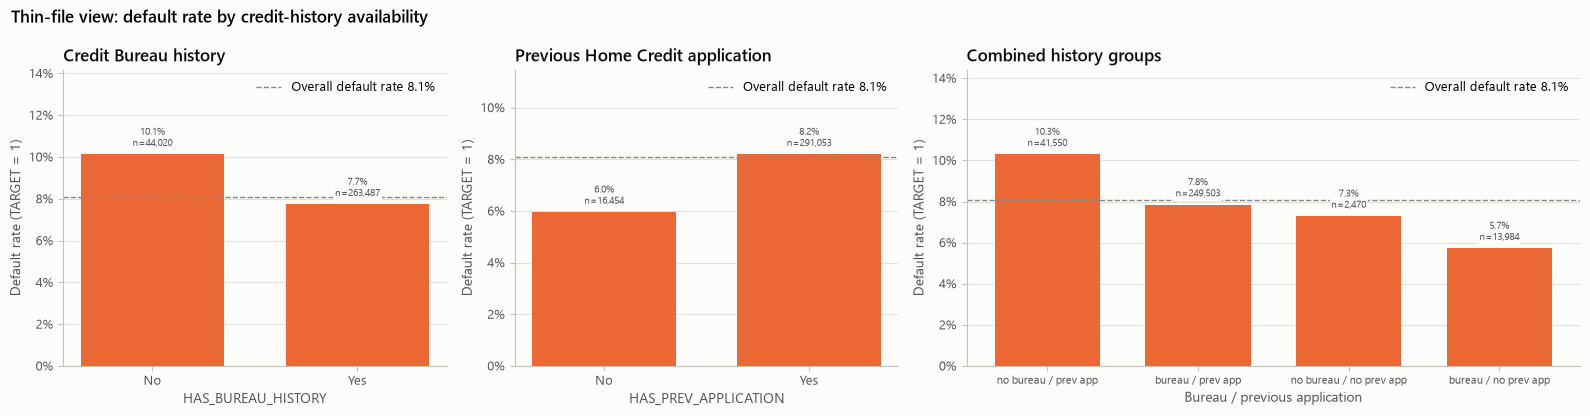

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.6]})
for ax, col, title in [(axes[0], "HAS_BUREAU_HISTORY", "Credit Bureau history"),
                       (axes[1], "HAS_PREV_APPLICATION", "Previous Home Credit application")]:
    table = flag_tables[col].rename(index={0: "No", 1: "Yes"})
    plot_rate_bars(table, ax, title, col, overall_rate=overall_rate, horizontal=False)
plot_rate_bars(combo_table, axes[2], "Combined history groups", "Bureau / previous application",
               overall_rate=overall_rate, horizontal=False)
axes[2].tick_params(axis="x", labelsize=8)
fig.suptitle("Thin-file view: default rate by credit-history availability", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
savefig(fig, "12_thin_file_groups.png")
plt.show()

**Insight:** 44,020 applicants (14.32%) have no Credit Bureau record (the thin-file group this project targets),
and they default more often (10.12%) than applicants with a bureau record (7.73%). The previous-application flag
points the other way: the 16,454 applicants (5.35%) with no previous Home Credit application default at 5.96% vs
8.19%. The riskiest segment is "no bureau history but a previous Home Credit application" (41,550 applicants,
10.29%), and only 2,470 applicants (0.80%) have neither source. So for 41,550 of the 44,020 bureau-less applicants,
Home Credit's own history is available as alternative data.

## 6. Key findings

1. **Strong class imbalance:** 24,825 of 307,511 applicants (8.07%) defaulted, so 91.93% accuracy is achievable
   by predicting "repaid" for everyone. Evaluation must use AUC / PR-AUC and the model must handle the imbalance.
2. **External scores are the strongest single signals:** `EXT_SOURCE_1/2/3` have the largest correlations with
   TARGET (−0.1553 to −0.1789), and defaulters' mean scores are 0.11–0.13 lower than those of repaid applicants.
3. **Age matters a lot:** default falls from 12.31% (age 20–24) to 3.72% (age 65–69).
4. **Socio-economic profile matters:** lower-secondary education 10.93% vs higher education 5.36%; low-skill
   labourers 17.16% vs accountants 4.83%; working applicants 9.59% vs pensioners 5.39%.
5. **The `DAYS_EMPLOYED` anomaly is informative:** the 55,374 applicants (18.01%) with the 365243 placeholder
   (almost all pensioners) default at 5.40% vs 8.66%, so it is kept as a flag rather than silently imputed.
6. **Lots of missing data, mostly building information:** 41 columns are more than 50% missing, 39 of them
   building-information columns; missingness is handled inside the models rather than by dropping rows.
7. **Affordability ratios are weak on their own:** the default rate varies by at most 2.29 percentage points
   across credit-to-income deciles, with no monotonic trend.
8. **Thin-file applicants are riskier:** the 44,020 applicants (14.32%) without bureau history default at 10.12% vs
   7.73% for the rest, but 41,550 of them have previous Home Credit applications, so alternative data exists for
   most of this group.